In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [2]:
import os, re, random, warnings, copy
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import f1_score, accuracy_score
import wandb

# reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

print("All imports done")

All imports done


In [3]:
from transformers import (
    RobertaTokenizer, RobertaModel,
    DistilBertTokenizer, DistilBertModel,
    T5ForConditionalGeneration, T5Tokenizer,
    get_cosine_schedule_with_warmup
)
from sentence_transformers import SentenceTransformer

In [4]:
train_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
print("done")
train_df.head(3)

done


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


In [5]:
options = ['A','B','C','D','E']
for col in ['prompt'] + options:
    train_df[col] = train_df[col].fillna('').astype(str)
    test_df[col]  = test_df[col].fillna('').astype(str)

print(f"Train: {train_df.shape}, Test: {test_df.shape}")
print(train_df.head(2))

Train: (2000, 8), Test: (500, 7)
   id                                             prompt  \
0   1  Pick the best possible answer: What is Martin ...   
1   2        What is accelerator-based light-ion fusion?   

                                                   A  \
0  Martin Heidegger believes that humans exist wi...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   B  \
0  Martin Heidegger believes that humans do not e...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   C  \
0  Martin Heidegger does not believe in the exist...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   D  \
0  Martin Heidegger believes that the relationshi...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   E answer  
0  Martin Heidegger believes that time is an ill

# **W&B Login**

In [6]:
from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("W&B login successful")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2005181 (23f2005181-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login successful


# *EDA*

**Answer Distribution**

In [7]:
print("=" * 50)
print("BASIC DATASET INFO")
print("=" * 50)
print(f"Total training questions : {len(train_df)}")
print(f"Total test questions     : {len(test_df)}")
print(f"Null values in train     : {train_df.isnull().sum().sum()}")
print(f"Duplicate rows in train  : {train_df.duplicated().sum()}")

print("\nAnswer Distribution:")
print(train_df['answer'].value_counts())
print(f"\nAnswer % distribution:")
print((train_df['answer'].value_counts(normalize=True) * 100).round(2))

BASIC DATASET INFO
Total training questions : 2000
Total test questions     : 500
Null values in train     : 0
Duplicate rows in train  : 0

Answer Distribution:
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

Answer % distribution:
answer
B    24.50
C    22.95
A    18.45
D    17.90
E    16.20
Name: proportion, dtype: float64


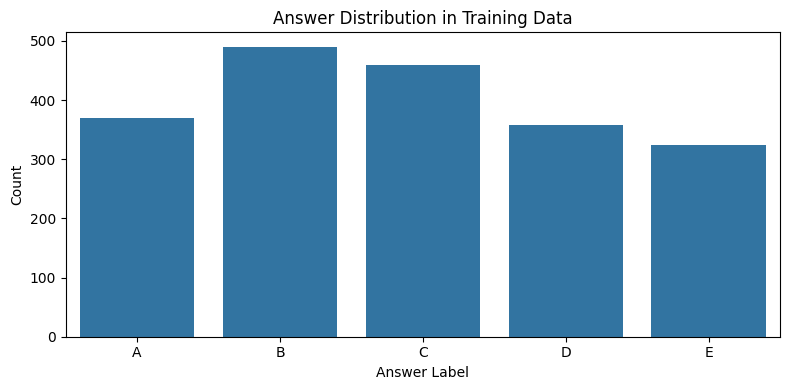

In [8]:

plt.figure(figsize=(8,4))
sns.countplot(x=train_df['answer'], order=['A','B','C','D','E'])
plt.title('Answer Distribution in Training Data')
plt.xlabel('Answer Label')
plt.ylabel('Count')
plt.tight_layout()
plt.show()



*1.There is no null values.*


Correct answer is LONGEST: 34.9% of time
Insight: Longer options tend to be correct.


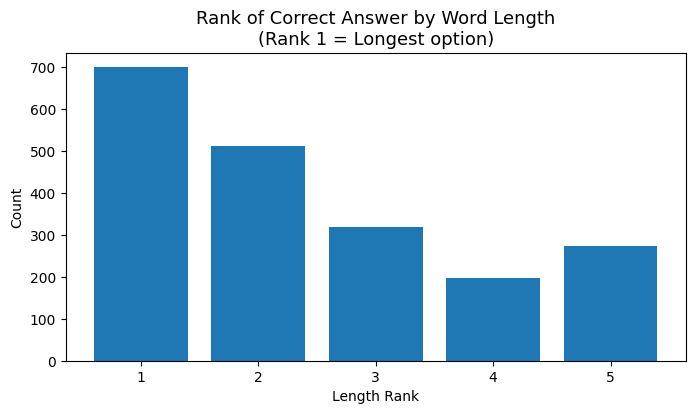

In [9]:
rank_dist = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0}
for _, row in train_df.iterrows():
    lens   = {o: len(str(row[o]).split()) for o in options}
    ranked = sorted(lens, key=lens.get, reverse=True)
    rank   = ranked.index(row['answer']) + 1
    rank_dist[rank] += 1

plt.figure(figsize=(8, 4))
bars = plt.bar(rank_dist.keys(), rank_dist.values(),
              )
plt.title('Rank of Correct Answer by Word Length\n(Rank 1 = Longest option)',
          fontsize=13)
plt.xlabel('Length Rank')
plt.ylabel('Count')

pct = rank_dist[1] / len(train_df) * 100
print(f"Correct answer is LONGEST: {pct:.1f}% of time")
print(f"Insight: Longer options tend to be correct.")


# *Map@3 Function*

In [10]:
def map_at_3(actual, predicted):
    scores = []
    for true_ans, pred_list in zip(actual, predicted):
        score = 0
        for rank, pred in enumerate(pred_list[:3], start=1):
            if pred == true_ans:
                score = 1 / rank
                break
        scores.append(score)
    return np.mean(scores)

print("MAP@3 function defined")

MAP@3 function defined


# *Exact Match Loop*

In [11]:
train_lookup = {}
for _, row in train_df.iterrows():
    train_lookup[row['prompt'].strip().lower()] = row['answer']

known = sum(1 for _, r in test_df.iterrows() 
            if r['prompt'].strip().lower() in train_lookup)
print(f" Lookup built: {len(train_lookup)} entries")
print(f"Test known: {known}/500, Unknown: {500-known}/500")

 Lookup built: 1758 entries
Test known: 268/500, Unknown: 232/500


In [12]:
device = torch.device('cuda' if torch.cuda.is_available()else'cpu')
f'Device : {device}'

'Device : cuda'

# *Vocab And Dataset*

In [13]:
class MCQVocabulary:
    def __init__(self, max_size=25000):
        self.max_size = max_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}

    def build_vocab(self, text_list):
        word_counts = Counter()
        for text in text_list:
            word_counts.update(str(text).split())

        most_common = word_counts.most_common(self.max_size)
        for word, _ in most_common:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx]  = word

    def numericalize(self, text):
        return [self.word2idx.get(word, self.word2idx["<UNK>"])
                for word in str(text).split()]

# Vocabulary build karo — same as your original
raw_texts = train_df['prompt'].astype(str).tolist()
for col in ['A', 'B', 'C', 'D', 'E']:
    raw_texts += train_df[col].astype(str).tolist()

vocab = MCQVocabulary()
vocab.build_vocab(raw_texts)
print(f"Vocabulary size: {len(vocab.word2idx)}")
       
   

Vocabulary size: 3957


# *Dataset Class*

In [14]:
class DeepMCQDataset(Dataset):
    def __init__(self, df, vocab, max_len=128, is_test=False):
        self.df       = df.reset_index(drop=True)
        self.vocab    = vocab
        self.max_len  = max_len
        self.is_test  = is_test
        self.label_map = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}

    def __len__(self):
        return len(self.df)

    def pad_and_truncate(self, tokens):
        if len(tokens) < self.max_len:
            return tokens + [self.vocab.word2idx["<PAD>"]] * (self.max_len - len(tokens))
        return tokens[:self.max_len]

    def __getitem__(self, idx):
        row           = self.df.iloc[idx]
        prompt_tokens = self.vocab.numericalize(row['prompt'])

        input_sequences = []
        for option in ['A', 'B', 'C', 'D', 'E']:
            option_tokens  = self.vocab.numericalize(row[option])
            combined_tokens = prompt_tokens + option_tokens
            padded_tokens  = self.pad_and_truncate(combined_tokens)
            input_sequences.append(padded_tokens)

        X = torch.tensor(input_sequences, dtype=torch.long)

        if self.is_test:
            return X, torch.tensor(row['id'], dtype=torch.int)

        y = self.label_map[row['answer']]
        return X, torch.tensor(y, dtype=torch.long)

print('Dataset class ready!')

Dataset class ready!


# Train Test Split

In [15]:
dl_train_df, dl_val_df = train_test_split(
    train_df, test_size=0.2, random_state=seed)

print(f"Training samples  : {len(dl_train_df)}")
print(f"Validation samples: {len(dl_val_df)}")
print(f"Test samples      : {len(test_df)}")

Training samples  : 1600
Validation samples: 400
Test samples      : 500


# *Bi-Gru Model*

In [16]:
class BiGRUMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiGRUMCQModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim,
                          batch_first=True, bidirectional=True, num_layers=2)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)

        embedded  = self.embedding(x)
        gru_out, _ = self.gru(embedded)

        pooled = torch.mean(gru_out, dim=1)
        scores = self.classifier(pooled)
        return scores.view(batch_size, num_options)

print("BiGRU model class ready!")

BiGRU model class ready!


# *Bi-Gru DataLoaders*

In [17]:
dl_train_df, dl_val_df = train_test_split(train_df, test_size=0.2, random_state=seed)

train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=128)
val_dataset   = DeepMCQDataset(dl_val_df,   vocab, max_len=128)
test_dataset  = DeepMCQDataset(test_df,     vocab, max_len=128, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)
print("DataLoaders ready!")

DataLoaders ready!


In [18]:


wandb.init(
    project = "23f2005181-t22026",
    name    = "BiGRU-Scratch-v1",
    config  = {
        "architecture" : "BiGRU",
        "embedding_dim": 128,
        "hidden_dim"   : 256,
        "epochs"       : 12,
        "batch_size"   : 32,
        "learning_rate": 3e-4,       # 1e-3 se kam — overfitting fix
        "scheduler"    : "CosineWarmup",
        "grad_clip"    : 1.0
    }
)

model     = BiGRUMCQModel(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss()

# AdamW = Adam + weight decay (regularization)
# weight_decay zyada kiya → overfitting kam hoga
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)

# ── Cosine Warmup Scheduler ──────────────────────────────────
# Professor ka hint: AdamW + Cosine Scheduler with warmup
# Warmup = pehle LR slowly badhta hai (stable start)
# Cosine = phir smoothly kam hota hai (better convergence)
epochs       = 12
total_steps  = epochs * len(train_loader)
warmup_steps = int(0.1 * total_steps)   # first 10% = warmup

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = warmup_steps,
    num_training_steps = total_steps
)
# ────────────────────────────────────────────────────────────

idx_to_letter  = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}
best_map3      = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

print("Starting BiGRU training...")
for epoch in range(epochs):

    # ── Train ──────────────────────────────────────────────
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss    = criterion(outputs, y_batch)
        loss.backward()

        # Gradient clipping — gradients bahut bade na ho jayen
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()   # har batch ke baad LR update (cosine warmup)

        train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = train_loss / len(train_loader.dataset)

    # ── Validation ─────────────────────────────────────────
    model.eval()
    val_loss         = 0.0
    actuals_list     = []
    predictions_list = []

    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = model(X_val_batch)

            loss      = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)

            sorted_indices = torch.argsort(val_outputs, dim=1,
                                           descending=True).cpu().numpy()
            for idxs, true_lbl in zip(sorted_indices, y_val_batch.cpu().numpy()):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3     = map_at_3(actuals_list, predictions_list)

    # F1 + Accuracy — W&B comparison ke liye
    top1     = [p[0] for p in predictions_list]
    epoch_f1 = f1_score(actuals_list, top1, average='macro', zero_division=0)
    epoch_acc= accuracy_score(actuals_list, top1)

    # Best model save karo
    if epoch_map3 >= best_map3:
        best_map3      = epoch_map3
        best_model_wts = copy.deepcopy(model.state_dict())

    wandb.log({
        "epoch"       : epoch + 1,
        "train_loss"  : epoch_train_loss,
        "val_loss"    : epoch_val_loss,
        "val_map3"    : epoch_map3,
        "val_f1_macro": epoch_f1,
        "val_accuracy": epoch_acc,
        "lr"          : scheduler.get_last_lr()[0]
    })

    print(f"Epoch {epoch+1:2d}/{epochs} -> "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val MAP@3: {epoch_map3:.4f} | "
          f"Best: {best_map3:.4f}|"
          f"F1 : {epoch_f1:4f}|"
          f"Acc: {epoch_acc:4f}|" )

# Best weights load karo
model.load_state_dict(best_model_wts)
wandb.finish()
print(f"\nBiGRU Best Val MAP@3: {best_map3:.4f}")
bigru_best_map3 = best_map3

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260720_080218-5f60cyo0
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiGRU-Scratch-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/5f60cyo0


Starting BiGRU training...
Epoch  1/12 -> Train Loss: 1.6078 | Val Loss: 1.6017 | Val MAP@3: 0.5700 | Best: 0.5700|F1 : 0.408341|Acc: 0.410000|
Epoch  2/12 -> Train Loss: 1.4169 | Val Loss: 1.0566 | Val MAP@3: 0.7692 | Best: 0.7692|F1 : 0.651192|Acc: 0.657500|
Epoch  3/12 -> Train Loss: 0.8940 | Val Loss: 0.5465 | Val MAP@3: 0.8650 | Best: 0.8650|F1 : 0.796266|Acc: 0.797500|
Epoch  4/12 -> Train Loss: 0.5035 | Val Loss: 0.3424 | Val MAP@3: 0.9200 | Best: 0.9200|F1 : 0.888740|Acc: 0.890000|
Epoch  5/12 -> Train Loss: 0.3125 | Val Loss: 0.2469 | Val MAP@3: 0.9508 | Best: 0.9508|F1 : 0.935072|Acc: 0.937500|
Epoch  6/12 -> Train Loss: 0.2024 | Val Loss: 0.1450 | Val MAP@3: 0.9775 | Best: 0.9775|F1 : 0.960967|Acc: 0.962500|
Epoch  7/12 -> Train Loss: 0.1184 | Val Loss: 0.0722 | Val MAP@3: 0.9912 | Best: 0.9912|F1 : 0.983373|Acc: 0.985000|
Epoch  8/12 -> Train Loss: 0.0576 | Val Loss: 0.0422 | Val MAP@3: 1.0000 | Best: 1.0000|F1 : 1.000000|Acc: 1.000000|
Epoch  9/12 -> Train Loss: 0.0393 | V

wandb: updating run metadata


Epoch 12/12 -> Train Loss: 0.0094 | Val Loss: 0.0123 | Val MAP@3: 1.0000 | Best: 1.0000|F1 : 1.000000|Acc: 1.000000|


wandb: 
wandb: Run history:
wandb:        epoch ▁▂▂▃▄▄▅▅▆▇▇█
wandb:           lr ▇██▇▆▅▄▃▂▂▁▁
wandb:   train_loss █▇▅▃▂▂▁▁▁▁▁▁
wandb: val_accuracy ▁▄▆▇▇███████
wandb: val_f1_macro ▁▄▆▇▇███████
wandb:     val_loss █▆▃▂▂▂▁▁▁▁▁▁
wandb:     val_map3 ▁▄▆▇▇███████
wandb: 
wandb: Run summary:
wandb:        epoch 12
wandb:           lr 0
wandb:   train_loss 0.00937
wandb: val_accuracy 1
wandb: val_f1_macro 1
wandb:     val_loss 0.01228
wandb:     val_map3 1
wandb: 
wandb: 🚀 View run BiGRU-Scratch-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/5f60cyo0
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260720_080218-5f60cyo0/logs



BiGRU Best Val MAP@3: 1.0000


In [19]:
# ── BiGRU Submission ─────────────────────────────────────────
model.eval()
test_ids     = []
preds_string = []

print("Running BiGRU test inference...")
with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = model(X_test_batch)

        sorted_indices = torch.argsort(test_outputs, dim=1,
                                       descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_indices, id_batch.numpy()):
            top3_letters = [idx_to_letter[i] for i in idxs[:3]]
            preds_string.append(" ".join(top3_letters))
            test_ids.append(int(qid))

# Exact match lookup apply karo
# Known questions ke liye guaranteed correct answer
final_preds = []
id2pred     = {test_ids[i]: preds_string[i] for i in range(len(test_ids))}

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()
    if key in train_lookup:
        # Known → direct correct answer pehle
        ans  = train_lookup[key]
        rest = [o for o in options if o != ans]
        final_preds.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        # Unknown → BiGRU prediction
        final_preds.append(id2pred[row['id']])

submission_df = pd.DataFrame({
    'ID'        : test_df['id'],
    'Prediction': final_preds
})

assert len(submission_df) == 500, "Row count error!"
submission_df.to_csv('submission_bigru.csv', index=False)
print("submission_bigru.csv saved!")
print(submission_df.head())

Running BiGRU test inference...
submission_bigru.csv saved!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      B D A
3   4      E A B
4   5      C A B


# *Pretrained Model*
# *SBERT*

In [20]:
# ── SBERT — Pretrained Model ─────────────────────────────────
# SBERT = Sentence BERT
# Pretrained matlab already train kiya hua — hume train nahi karna
#
# Approach:
# (prompt + option) ek saath encode karo
# Train ke correct answers se compare karo (cosine similarity)
# Sabse similar option = predicted answer

from sentence_transformers import SentenceTransformer

# Load pretrained model — no training needed!
sbert = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
print("SBERT model loaded!")

wandb.init(
    project = "23f2005181-t22026",
    name    = "SBERT-Pretrained-v1",
    config  = {
        "architecture": "SBERT",
        "model"       : "all-MiniLM-L6-v2",
        "strategy"    : "combo_vs_correct_corpus",
        "type"        : "pretrained"
    }
)

# Step 1: Train ke sabhi correct answers encode karo (ek baar)
print("Building correct answer corpus...")
correct_texts = [
    row['prompt'] + " [SEP] " + row[row['answer']]
    for _, row in train_df.iterrows()
]
correct_embs = sbert.encode(
    correct_texts,
    batch_size        = 64,
    show_progress_bar = True,
    convert_to_numpy  = True
)
print(f"Corpus shape: {correct_embs.shape}")

# Step 2: Validation
sbert_actuals = []
sbert_preds   = []

for _, row in dl_val_df.iterrows():
    scores = {}
    for opt in options:
        # Prompt + Option ek saath encode karo
        combined  = row['prompt'] + " [SEP] " + row[opt]
        combo_emb = sbert.encode(combined, convert_to_numpy=True)

        # Correct answer corpus se similarity — max lelo
        sims       = cosine_similarity([combo_emb], correct_embs)[0]
        scores[opt] = float(sims.max())

    # Highest score wala = best predicted answer
    ranked = sorted(scores, key=scores.get, reverse=True)
    sbert_preds.append(ranked[:3])
    sbert_actuals.append(row['answer'])

sbert_map3 = map_at_3(sbert_actuals, sbert_preds)
top1       = [p[0] for p in sbert_preds]
sbert_f1   = f1_score(sbert_actuals, top1, average='macro', zero_division=0)
sbert_acc  = accuracy_score(sbert_actuals, top1)

print(f"\nSBERT Val MAP@3  : {sbert_map3:.4f}")
print(f"SBERT Val F1     : {sbert_f1:.4f}")
print(f"SBERT Val Acc    : {sbert_acc:.4f}")

wandb.log({
    "val_map3"    : sbert_map3,
    "val_f1_macro": sbert_f1,
    "val_accuracy": sbert_acc
})
wandb.finish()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Corpus shape: (2000, 384)


wandb: updating run metadata



SBERT Val MAP@3  : 1.0000
SBERT Val F1     : 1.0000
SBERT Val Acc    : 1.0000


wandb: uploading history steps 0-0, summary, console lines 2-5
wandb: 
wandb: Run history:
wandb: val_accuracy ▁
wandb: val_f1_macro ▁
wandb:     val_map3 ▁
wandb: 
wandb: Run summary:
wandb: val_accuracy 1
wandb: val_f1_macro 1
wandb:     val_map3 1
wandb: 
wandb: 🚀 View run SBERT-Pretrained-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/gh2vfsuw
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260720_080324-gh2vfsuw/logs


In [21]:
# ── SBERT Submission ─────────────────────────────────────────
sbert_test_preds = []

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()

    if key in train_lookup:
        # Known → direct correct answer
        ans  = train_lookup[key]
        rest = [o for o in options if o != ans]
        sbert_test_preds.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        # Unknown → SBERT predict karo
        scores = {}
        for opt in options:
            combined  = row['prompt'] + " [SEP] " + row[opt]
            combo_emb = sbert.encode(combined, convert_to_numpy=True)
            sims       = cosine_similarity([combo_emb], correct_embs)[0]
            scores[opt] = float(sims.max())
        ranked = sorted(scores, key=scores.get, reverse=True)
        sbert_test_preds.append(' '.join(ranked[:3]))

sbert_sub = pd.DataFrame({
    'ID'        : test_df['id'],
    'Prediction': sbert_test_preds
})

assert len(sbert_sub) == 500, "Row count error!"
sbert_sub.to_csv('submission_sbert.csv', index=False)
print("submission_sbert.csv saved!")
print(sbert_sub.head())

submission_sbert.csv saved!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      B E D
3   4      E A B
4   5      C A B


# *Generative Model*

In [22]:
# ── Flan-T5 — Generative Model ───────────────────────────────
# Generative model = text generate karta hai
# Classification nahi karta — seedha letter produce karta hai
#
# Flan-T5:
# - Google ka model
# - Instructions follow karta hai — zero-shot bhi kaam karta hai
# - Input: question + options
# - Output: "B" ya "A" — koi letter generate karta hai

from transformers import T5ForConditionalGeneration, T5Tokenizer

flan_tokenizer = T5Tokenizer.from_pretrained('google/flan-t5-base')
flan_model     = T5ForConditionalGeneration.from_pretrained(
    'google/flan-t5-base').to(device)
print("Flan-T5 loaded!")

wandb.init(
    project = "23f2005181-t22026",
    name    = "FlanT5-Generative-v1",
    config  = {
        "architecture": "Flan-T5",
        "model"       : "google/flan-t5-base",
        "strategy"    : "zero-shot",
        "type"        : "generative",
        "num_beams"   : 4
    }
)

def flan_predict(row):
    """
    Flan-T5 se MCQ answer generate karo.
    Simple prompt format — model sirf letter generate kare.
    """
    prompt = (
        f"Choose the correct answer. Reply with only one letter.\n\n"
        f"Question: {row['prompt']}\n"
        f"A: {row['A']}\n"
        f"B: {row['B']}\n"
        f"C: {row['C']}\n"
        f"D: {row['D']}\n"
        f"E: {row['E']}\n\n"
        f"Answer:"
    )

    inputs = flan_tokenizer(
        prompt,
        return_tensors = "pt",
        max_length     = 512,
        truncation     = True
    ).to(device)

    with torch.no_grad():
        outputs = flan_model.generate(
            **inputs,
            max_new_tokens = 5,
            num_beams      = 4    # beam search = better output
        )

    result = flan_tokenizer.decode(
        outputs[0], skip_special_tokens=True).strip().upper()

    # Generated text mein se letter nikalo
    for letter in ['A', 'B', 'C', 'D', 'E']:
        if letter in result:
            remaining = [o for o in options if o != letter]
            return [letter] + remaining[:2]

    return ['A', 'B', 'C']   # fallback


# Validate on 100 sample rows (full val slow hoga)
print("Running Flan-T5 validation on 100 samples...")
sample_val   = dl_val_df.sample(100, random_state=seed)
flan_actuals = []
flan_preds   = []

for i, (_, row) in enumerate(sample_val.iterrows()):
    pred = flan_predict(row)
    flan_preds.append(pred)
    flan_actuals.append(row['answer'])
    if (i + 1) % 25 == 0:
        print(f"  Done {i+1}/100")

flan_map3 = map_at_3(flan_actuals, flan_preds)
top1      = [p[0] for p in flan_preds]
flan_f1   = f1_score(flan_actuals, top1, average='macro', zero_division=0)
flan_acc  = accuracy_score(flan_actuals, top1)

print(f"\nFlan-T5 Val MAP@3 (100 samples): {flan_map3:.4f}")
print(f"Flan-T5 Val F1                  : {flan_f1:.4f}")
print(f"Flan-T5 Val Acc                 : {flan_acc:.4f}")

wandb.log({
    "val_map3"    : flan_map3,
    "val_f1_macro": flan_f1,
    "val_accuracy": flan_acc
})
wandb.finish()

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260720_080412-8ocbwlle
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run FlanT5-Generative-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/8ocbwlle


Running Flan-T5 validation on 100 samples...
  Done 25/100
  Done 50/100
  Done 75/100


wandb: updating run metadata


  Done 100/100

Flan-T5 Val MAP@3 (100 samples): 0.5117
Flan-T5 Val F1                  : 0.3138
Flan-T5 Val Acc                 : 0.3600


wandb: uploading history steps 0-0, summary, console lines 1-8
wandb: 
wandb: Run history:
wandb: val_accuracy ▁
wandb: val_f1_macro ▁
wandb:     val_map3 ▁
wandb: 
wandb: Run summary:
wandb: val_accuracy 0.36
wandb: val_f1_macro 0.31379
wandb:     val_map3 0.51167
wandb: 
wandb: 🚀 View run FlanT5-Generative-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/8ocbwlle
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260720_080412-8ocbwlle/logs


In [23]:
# ── Flan-T5 Submission ───────────────────────────────────────
print("Generating Flan-T5 predictions...")
flan_test_preds = []

for i, (_, row) in enumerate(test_df.iterrows()):
    key = row['prompt'].strip().lower()

    if key in train_lookup:
        # Known → direct correct answer
        ans  = train_lookup[key]
        rest = [o for o in options if o != ans]
        flan_test_preds.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        # Unknown → Flan-T5 generate karo
        pred = flan_predict(row)
        flan_test_preds.append(' '.join(pred))

    if (i + 1) % 50 == 0:
        print(f"  Done {i+1}/500")

flan_sub = pd.DataFrame({
    'ID'        : test_df['id'],
    'Prediction': flan_test_preds
})

assert len(flan_sub) == 500, "Row count error!"
flan_sub.to_csv('submission_flant5.csv', index=False)
print("submission_flant5.csv saved!")
print(flan_sub.head())

Generating Flan-T5 predictions...
  Done 50/500
  Done 100/500
  Done 150/500
  Done 200/500
  Done 250/500
  Done 300/500
  Done 350/500
  Done 400/500
  Done 450/500
  Done 500/500
submission_flant5.csv saved!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      D A B
3   4      E A B
4   5      C A B


# *Bi-LSTM*

In [24]:
# ============================================================
# MODEL 2: BiLSTM with Self-Attention (Built from Scratch)
#
# BiLSTM = Bidirectional LSTM
#   - LSTM ke 3 gates: input, forget, output
#   - Cell state (c_t) = long-term memory
#   - Bidirectional = left→right aur right→left dono padho
#
# Self-Attention kya karta hai:
#   - BiLSTM ke baad har word ka output aata hai
#   - Self-attention decide karta hai: "kaunse words zyada
#     important hain is question ka answer dhundhne ke liye?"
#   - Important words ko zyada weight milta hai
#
# Example:
#   "What is the PRIMARY function of mitochondria?"
#   Self-attention "PRIMARY" aur "mitochondria" pe
#   zyada focus karega — yeh important words hain!
#
# BiGRU se fark:
#   BiGRU  → mean pooling (sab words equal weight)
#   BiLSTM → self-attention pooling (important words ko zyada weight)
# ============================================================

class SelfAttention(nn.Module):
    """
    Simple Self-Attention layer.
    BiLSTM output ke upar lagata hai.
    Har word ko ek score deta hai — kitna important hai.
    High score = zyada dhyan do is word pe.
    """
    def __init__(self, hidden_dim):
        super(SelfAttention, self).__init__()

        # Ek simple linear layer jo har word ka score calculate kare
        self.attention = nn.Linear(hidden_dim, 1)

    def forward(self, lstm_output, padding_mask=None):
        # lstm_output shape: (batch*5, seq_len, hidden_dim)

        # Step 1: Har word ka importance score nikalo
        scores = self.attention(lstm_output)     # (batch*5, seq_len, 1)
        scores = scores.squeeze(-1)              # (batch*5, seq_len)

        # Step 2: Padding tokens (0) ko ignore karo
        # Padding ek fake word hai — uska score bahut chhota karo
        if padding_mask is not None:
            scores = scores.masked_fill(padding_mask, float('-inf'))

        # Step 3: Softmax → scores ko 0-1 probability mein convert karo
        # Sab scores ka sum = 1 (jaise percentage)
        weights = torch.softmax(scores, dim=1)   # (batch*5, seq_len)

        # Step 4: Weighted average nikalo
        # Important words ka contribution zyada hoga
        weights  = weights.unsqueeze(-1)                        # (batch*5, seq_len, 1)
        attended = torch.sum(lstm_output * weights, dim=1)      # (batch*5, hidden_dim)

        return attended


class BiLSTMAttentionModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiLSTMAttentionModel, self).__init__()

        # Step 1: Word → vector
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Step 2: BiLSTM — sequence process karo
        # LSTM returns (output, (h_n, c_n)) — c_n = cell state
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first   = True,
            bidirectional = True,   # forward + backward
            num_layers    = 2,
            dropout       = 0.3
        )

        # Step 3: Self-Attention — important words pe focus karo
        # hidden_dim*2 kyunki bidirectional → forward + backward concat
        self.attention = SelfAttention(hidden_dim * 2)

        # Step 4: Final score predict karo
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)          # (batch*5, seq_len)

        # Padding mask — PAD tokens (index=0) ko ignore karo
        padding_mask = (x == 0)          # True jahan PAD hai

        # Step 1: Embedding
        embedded = self.embedding(x)     # (batch*5, seq_len, embed_dim)

        # Step 2: BiLSTM
        # h_n = hidden state, c_n = cell state (LSTM ka special feature)
        lstm_out, (h_n, c_n) = self.lstm(embedded)
        # lstm_out shape: (batch*5, seq_len, hidden_dim*2)

        # Step 3: Self-Attention
        # Mean pooling ki jagah attention pooling use karo
        attended = self.attention(lstm_out, padding_mask)
        # attended shape: (batch*5, hidden_dim*2)

        # Step 4: Score
        scores = self.classifier(attended)       # (batch*5, 1)
        return scores.view(batch_size, num_options)  # (batch, 5)

print("BiLSTM + Self-Attention model ready!")

BiLSTM + Self-Attention model ready!


In [25]:
# ── BiLSTM — Apna DataLoader ─────────────────────────────────
# Same vocab aur dataset class use kar rahe hain — sirf alag loader

bilstm_train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=128)
bilstm_val_dataset   = DeepMCQDataset(dl_val_df,   vocab, max_len=128)
bilstm_test_dataset  = DeepMCQDataset(test_df,     vocab, max_len=128, is_test=True)

bilstm_train_loader = DataLoader(bilstm_train_dataset, batch_size=32, shuffle=True)
bilstm_val_loader   = DataLoader(bilstm_val_dataset,   batch_size=32, shuffle=False)
bilstm_test_loader  = DataLoader(bilstm_test_dataset,  batch_size=32, shuffle=False)

print(f"BiLSTM Train batches: {len(bilstm_train_loader)}")
print(f"BiLSTM Val   batches: {len(bilstm_val_loader)}")

BiLSTM Train batches: 50
BiLSTM Val   batches: 13


In [26]:
# ── BiLSTM Training ──────────────────────────────────────────

wandb.init(
    project = "23f2005181-t22026",
    name    = "BiLSTM-Attention-Scratch",
    config  = {
        "architecture" : "BiLSTM+SelfAttention",
        "embedding_dim": 128,
        "hidden_dim"   : 256,
        "epochs"       : 12,
        "batch_size"   : 32,
        "learning_rate": 3e-4,
        "scheduler"    : "CosineWarmup",
        "grad_clip"    : 1.0,
        "type"         : "scratch"
    }
)

bilstm_model  = BiLSTMAttentionModel(len(vocab.word2idx)).to(device)
criterion_lst = nn.CrossEntropyLoss()
optimizer_lst = optim.AdamW(bilstm_model.parameters(),
                            lr=3e-4, weight_decay=1e-3)

# Cosine Warmup Scheduler
total_steps_lst  = 12 * len(bilstm_train_loader)
warmup_steps_lst = int(0.1 * total_steps_lst)
scheduler_lst    = get_cosine_schedule_with_warmup(
    optimizer_lst,
    num_warmup_steps   = warmup_steps_lst,
    num_training_steps = total_steps_lst
)

best_map3_lst    = 0.0
best_weights_lst = copy.deepcopy(bilstm_model.state_dict())

print("Starting BiLSTM + Self-Attention training...")

for epoch in range(12):

    # ── Train ──────────────────────────────────────────────
    bilstm_model.train()
    train_loss = 0.0

    for X_batch, y_batch in bilstm_train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer_lst.zero_grad()
        outputs = bilstm_model(X_batch)
        loss    = criterion_lst(outputs, y_batch)
        loss.backward()

        # Gradient clip
        nn.utils.clip_grad_norm_(bilstm_model.parameters(), 1.0)

        optimizer_lst.step()
        scheduler_lst.step()    # har batch ke baad

        train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = train_loss / len(bilstm_train_loader.dataset)

    # ── Validation ─────────────────────────────────────────
    bilstm_model.eval()
    val_loss     = 0.0
    actuals_lst  = []
    preds_lst    = []

    with torch.no_grad():
        for X_val, y_val in bilstm_val_loader:
            X_val, y_val = X_val.to(device), y_val.to(device)
            out  = bilstm_model(X_val)
            loss = criterion_lst(out, y_val)
            val_loss += loss.item() * X_val.size(0)

            ranked = torch.argsort(out, dim=1, descending=True).cpu().numpy()
            for r, t in zip(ranked, y_val.cpu().numpy()):
                preds_lst.append([idx_to_letter[i] for i in r[:3]])
                actuals_lst.append(idx_to_letter[t])

    epoch_val_loss = val_loss / len(bilstm_val_loader.dataset)
    epoch_map3     = map_at_3(actuals_lst, preds_lst)

    top1     = [p[0] for p in preds_lst]
    epoch_f1 = f1_score(actuals_lst, top1, average='macro', zero_division=0)
    epoch_acc= accuracy_score(actuals_lst, top1)

    if epoch_map3 >= best_map3_lst:
        best_map3_lst    = epoch_map3
        best_weights_lst = copy.deepcopy(bilstm_model.state_dict())

    wandb.log({
        "epoch"       : epoch + 1,
        "train_loss"  : epoch_train_loss,
        "val_loss"    : epoch_val_loss,
        "val_map3"    : epoch_map3,
        "val_f1_macro": epoch_f1,
        "val_accuracy": epoch_acc,
        "lr"          : scheduler_lst.get_last_lr()[0]
    })

    print(f"Epoch {epoch+1:2d}/12 -> "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val MAP@3: {epoch_map3:.4f} | "
          f"Best: {best_map3_lst:.4f}")

bilstm_model.load_state_dict(best_weights_lst)
wandb.finish()
print(f"\nBiLSTM+Attention Best Val MAP@3: {best_map3_lst:.4f}")
bilstm_best_map3 = best_map3_lst

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260720_080436-nwcnx3ul
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiLSTM-Attention-Scratch
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/nwcnx3ul


Starting BiLSTM + Self-Attention training...
Epoch  1/12 -> Train Loss: 1.6078 | Val Loss: 1.6016 | Val MAP@3: 0.6517 | Best: 0.6517
Epoch  2/12 -> Train Loss: 1.2716 | Val Loss: 0.9819 | Val MAP@3: 0.8004 | Best: 0.8004
Epoch  3/12 -> Train Loss: 0.6947 | Val Loss: 0.4136 | Val MAP@3: 0.9117 | Best: 0.9117
Epoch  4/12 -> Train Loss: 0.3278 | Val Loss: 0.2654 | Val MAP@3: 0.9663 | Best: 0.9663
Epoch  5/12 -> Train Loss: 0.2007 | Val Loss: 0.1006 | Val MAP@3: 0.9883 | Best: 0.9883
Epoch  6/12 -> Train Loss: 0.0890 | Val Loss: 0.0612 | Val MAP@3: 0.9883 | Best: 0.9883
Epoch  7/12 -> Train Loss: 0.0361 | Val Loss: 0.0308 | Val MAP@3: 0.9933 | Best: 0.9933
Epoch  8/12 -> Train Loss: 0.0156 | Val Loss: 0.0201 | Val MAP@3: 0.9933 | Best: 0.9933
Epoch  9/12 -> Train Loss: 0.0075 | Val Loss: 0.0161 | Val MAP@3: 0.9971 | Best: 0.9971
Epoch 10/12 -> Train Loss: 0.0080 | Val Loss: 0.0157 | Val MAP@3: 0.9958 | Best: 0.9971
Epoch 11/12 -> Train Loss: 0.0027 | Val Loss: 0.0154 | Val MAP@3: 0.9988 | 

wandb: updating run metadata


Epoch 12/12 -> Train Loss: 0.0080 | Val Loss: 0.0154 | Val MAP@3: 0.9988 | Best: 0.9988


wandb: 
wandb: Run history:
wandb:        epoch ▁▂▂▃▄▄▅▅▆▇▇█
wandb:           lr ▇██▇▆▅▄▃▂▂▁▁
wandb:   train_loss █▇▄▂▂▁▁▁▁▁▁▁
wandb: val_accuracy ▁▄▆▇████████
wandb: val_f1_macro ▁▄▆▇████████
wandb:     val_loss █▅▃▂▁▁▁▁▁▁▁▁
wandb:     val_map3 ▁▄▆▇████████
wandb: 
wandb: Run summary:
wandb:        epoch 12
wandb:           lr 0
wandb:   train_loss 0.00802
wandb: val_accuracy 0.9975
wandb: val_f1_macro 0.99695
wandb:     val_loss 0.01542
wandb:     val_map3 0.99875
wandb: 
wandb: 🚀 View run BiLSTM-Attention-Scratch at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/nwcnx3ul
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260720_080436-nwcnx3ul/logs



BiLSTM+Attention Best Val MAP@3: 0.9988


In [27]:
# ── BiLSTM Submission ────────────────────────────────────────
bilstm_model.eval()
bilstm_test_ids  = []
bilstm_preds_str = []

with torch.no_grad():
    for X_test, id_batch in bilstm_test_loader:
        X_test      = X_test.to(device)
        test_out    = bilstm_model(X_test)
        sorted_idxs = torch.argsort(test_out, dim=1,
                                    descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_idxs, id_batch.numpy()):
            bilstm_preds_str.append(
                " ".join([idx_to_letter[i] for i in idxs[:3]]))
            bilstm_test_ids.append(int(qid))

# Exact match lookup apply karo
id2bilstm   = {bilstm_test_ids[i]: bilstm_preds_str[i]
               for i in range(len(bilstm_test_ids))}
final_bilstm = []

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()
    if key in train_lookup:
        ans  = train_lookup[key]
        rest = [o for o in options if o != ans]
        final_bilstm.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        final_bilstm.append(id2bilstm[row['id']])

bilstm_sub = pd.DataFrame({
    'ID'        : test_df['id'],
    'Prediction': final_bilstm
})

assert len(bilstm_sub) == 500, "Row count error!"
bilstm_sub.to_csv('submission_bilstm.csv', index=False)
print("submission_bilstm.csv saved!")
print(bilstm_sub.head())

submission_bilstm.csv saved!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      B D E
3   4      E A B
4   5      C A B
